Premiere exploration des données de asthme -passage aux urgances

In [1]:
#import des librairies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [2]:
df_asthme = pd.read_csv(
    "../data/raw/Sante/asthme-passages-aux-urgences-et-actes-sos-medecins-dep.csv"
)
df_asthme.head()

,Semaine,1er jour de la semaine,Département,Région,Classe d'âge,Taux de passages aux urgences pour asthme,Taux d'hospitalisations après passages aux urgences pour asthme,Taux d'actes médicaux SOS médecins pour asthme,Département Code,Région Code
0,2026-S40,2026-09-28,Haute-Corse,Corse,65 ans ou plus,318.471338,0.000000,NaN,2B,94
1,2026-S40,2026-09-28,Gard,Occitanie,15-64 ans,166.805671,270.270270,1869.158878,30,76
2,2026-S40,2026-09-28,Haute-Garonne,Occitanie,00-14 ans,2232.746955,3875.968992,1041.666667,31,76
3,2026-S40,2026-09-28,Haute-Garonne,Occitanie,65 ans ou plus,341.296928,357.781753,0.000000,31,76
4,2026-S40,2026-09-28,Gers,Occitanie,00-14 ans,2777.777778,11111.111111,NaN,32,76


In [5]:
df_asthme2 = df_asthme.copy()
# 1. Tranformation de la date en numero de semaine
# nettoyage
df_asthme2.columns = (
    df_asthme2.columns
    .str.replace(" ", "_")
    .str.strip()
)

#Renommer les colonnes

df_asthme2 = df_asthme2.rename(columns={
    "Taux_de_passages_aux_urgences_pour_asthme": "taux_urgences",
    "Taux_d'hospitalisations_après_passages_aux_urgences_pour_asthme": "taux_hospitalisations",
    "Taux_d'actes_médicaux_SOS_médecins_pour_asthme": "taux_sos"
})


#transformer la colonne "1er_jour_de_la_semaine" en datetime pour extraire le mois et l'année
df_asthme2["1er_jour_de_la_semaine"] = pd.to_datetime(df_asthme2["1er_jour_de_la_semaine"])

# Extraire le mois et l'année
df_asthme2["mois"] = df_asthme2["1er_jour_de_la_semaine"].dt.month
df_asthme2["annee"] = df_asthme2["1er_jour_de_la_semaine"].dt.year

display(df_asthme2.head())
df_asthme2.info()

,Semaine,1er_jour_de_la_semaine,Département,Région,Classe_d'âge,taux_urgences,taux_hospitalisations,taux_sos,Département_Code,Région_Code,mois,annee
0,2026-S40,2026-09-28,Haute-Corse,Corse,65 ans ou plus,318.471338,0.000000,NaN,2B,94,9,2026
1,2026-S40,2026-09-28,Gard,Occitanie,15-64 ans,166.805671,270.270270,1869.158878,30,76,9,2026
2,2026-S40,2026-09-28,Haute-Garonne,Occitanie,00-14 ans,2232.746955,3875.968992,1041.666667,31,76,9,2026
3,2026-S40,2026-09-28,Haute-Garonne,Occitanie,65 ans ou plus,341.296928,357.781753,0.000000,31,76,9,2026
4,2026-S40,2026-09-28,Gers,Occitanie,00-14 ans,2777.777778,11111.111111,NaN,32,76,9,2026


<class 'pandas.DataFrame'>
RangeIndex: 121200 entries, 0 to 121199
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   Semaine                 121200 non-null  str           
 1   1er_jour_de_la_semaine  121200 non-null  datetime64[us]
 2   Département             121200 non-null  str           
 3   Région                  121200 non-null  str           
 4   Classe_d'âge            121200 non-null  str           
 5   taux_urgences           120700 non-null  float64       
 6   taux_hospitalisations   120116 non-null  float64       
 7   taux_sos                54678 non-null   float64       
 8   Département_Code        121200 non-null  str           
 9   Région_Code             121200 non-null  int64         
 10  mois                    121200 non-null  int32         
 11  annee                   121200 non-null  int32         
dtypes: datetime64[us](1), float64(3), int32(2

Visualisation des jeux de données

1. Distribution des taux


Nb de valeurs nulles dans taux_urgences : 13739
Nb de valeurs nulles dans taux_hospitalisations : 36414
Nb de valeurs nulles dans taux_sos : 6416


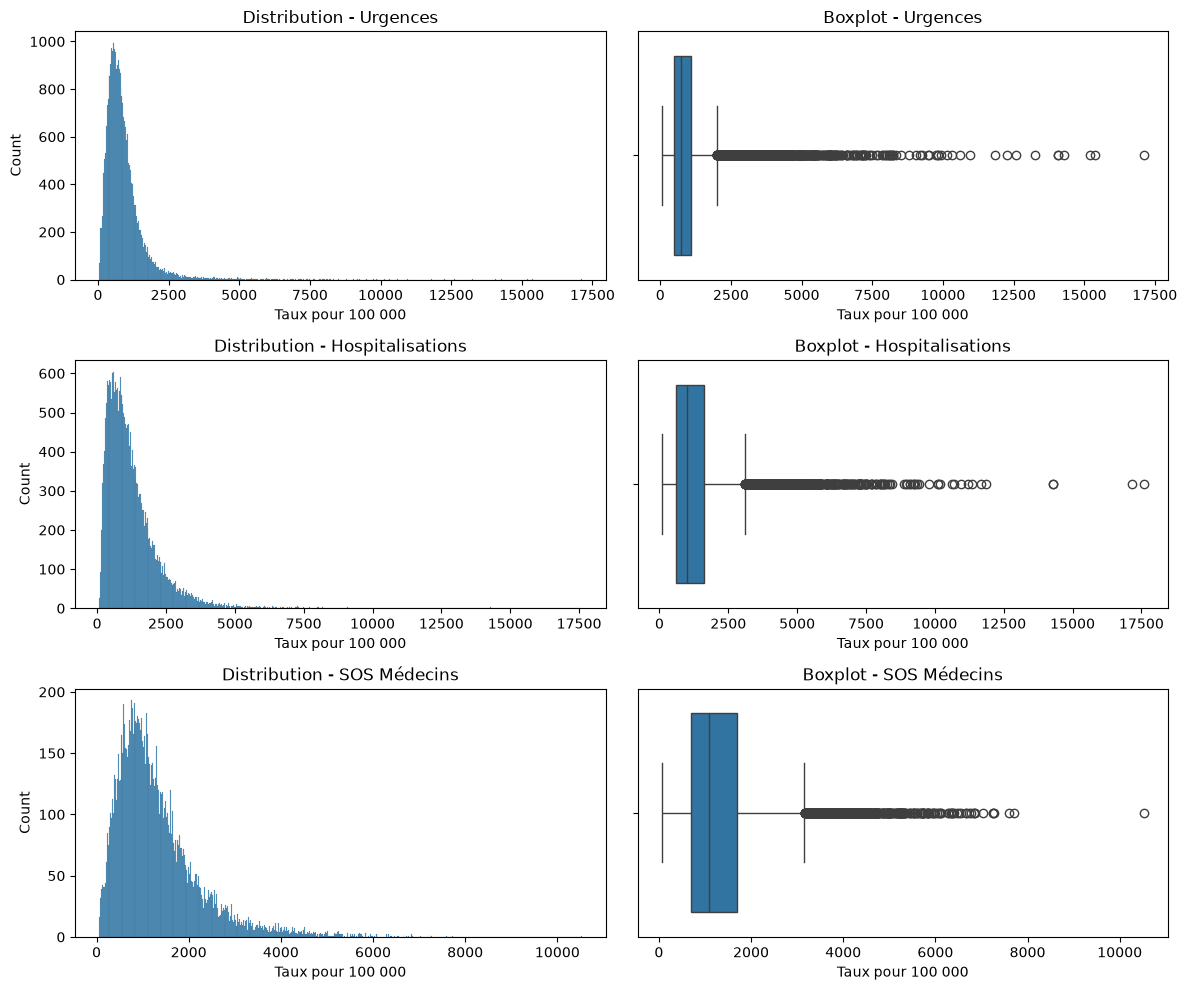

In [6]:
#Histogramme de la distribution des taux d'urgences 

print("Nb de valeurs nulles dans taux_urgences :", (df_asthme2["taux_urgences"] == 0).sum())
print("Nb de valeurs nulles dans taux_hospitalisations :", (df_asthme2["taux_hospitalisations"] == 0).sum())
print("Nb de valeurs nulles dans taux_sos :", (df_asthme2["taux_sos"] == 0).sum())    

df_tous_ages = df_asthme2.loc[df_asthme2["Classe_d'âge"] == "Tous âges"].copy()     #je selectionne uniquement les lignes correspondant à "Tous âges" pour l'analyse de distribution des taux d'urgences, hospitalisations et SOS medecins

colonnes = ["taux_urgences", "taux_hospitalisations", "taux_sos"]
titres = ["Urgences", "Hospitalisations", "SOS Médecins"]

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for i, col in enumerate(colonnes):
    # Exclure les NaN et les 0 uniquement pour la visualisation
    valeurs = df_tous_ages[col].dropna()                #exclure les NaN uniquement pour la visualisation
    valeurs = valeurs[valeurs != 0]                     #exclure les 0 uniquement pour la visualisation

    # Histogramme
    sns.histplot(valeurs, bins=520, ax=axes[i, 0])
    axes[i, 0].set_title(f"Distribution - {titres[i]}")
    axes[i, 0].set_xlabel("Taux pour 100 000")

    # Boxplot
    sns.boxplot(x=valeurs, ax=axes[i, 1])  #showfliers=False pour masquer les valeurs aberrantes/extremes
    axes[i, 1].set_title(f"Boxplot - {titres[i]}")
    axes[i, 1].set_xlabel("Taux pour 100 000")

plt.tight_layout()
plt.show()

Beacoup de donnée, reste difficile à interpreter
Attention, il y beacoup de valeurs 0, et beacoup des valeurs manquantes

2. A Comparer les distributions par mois, année (tout departement)

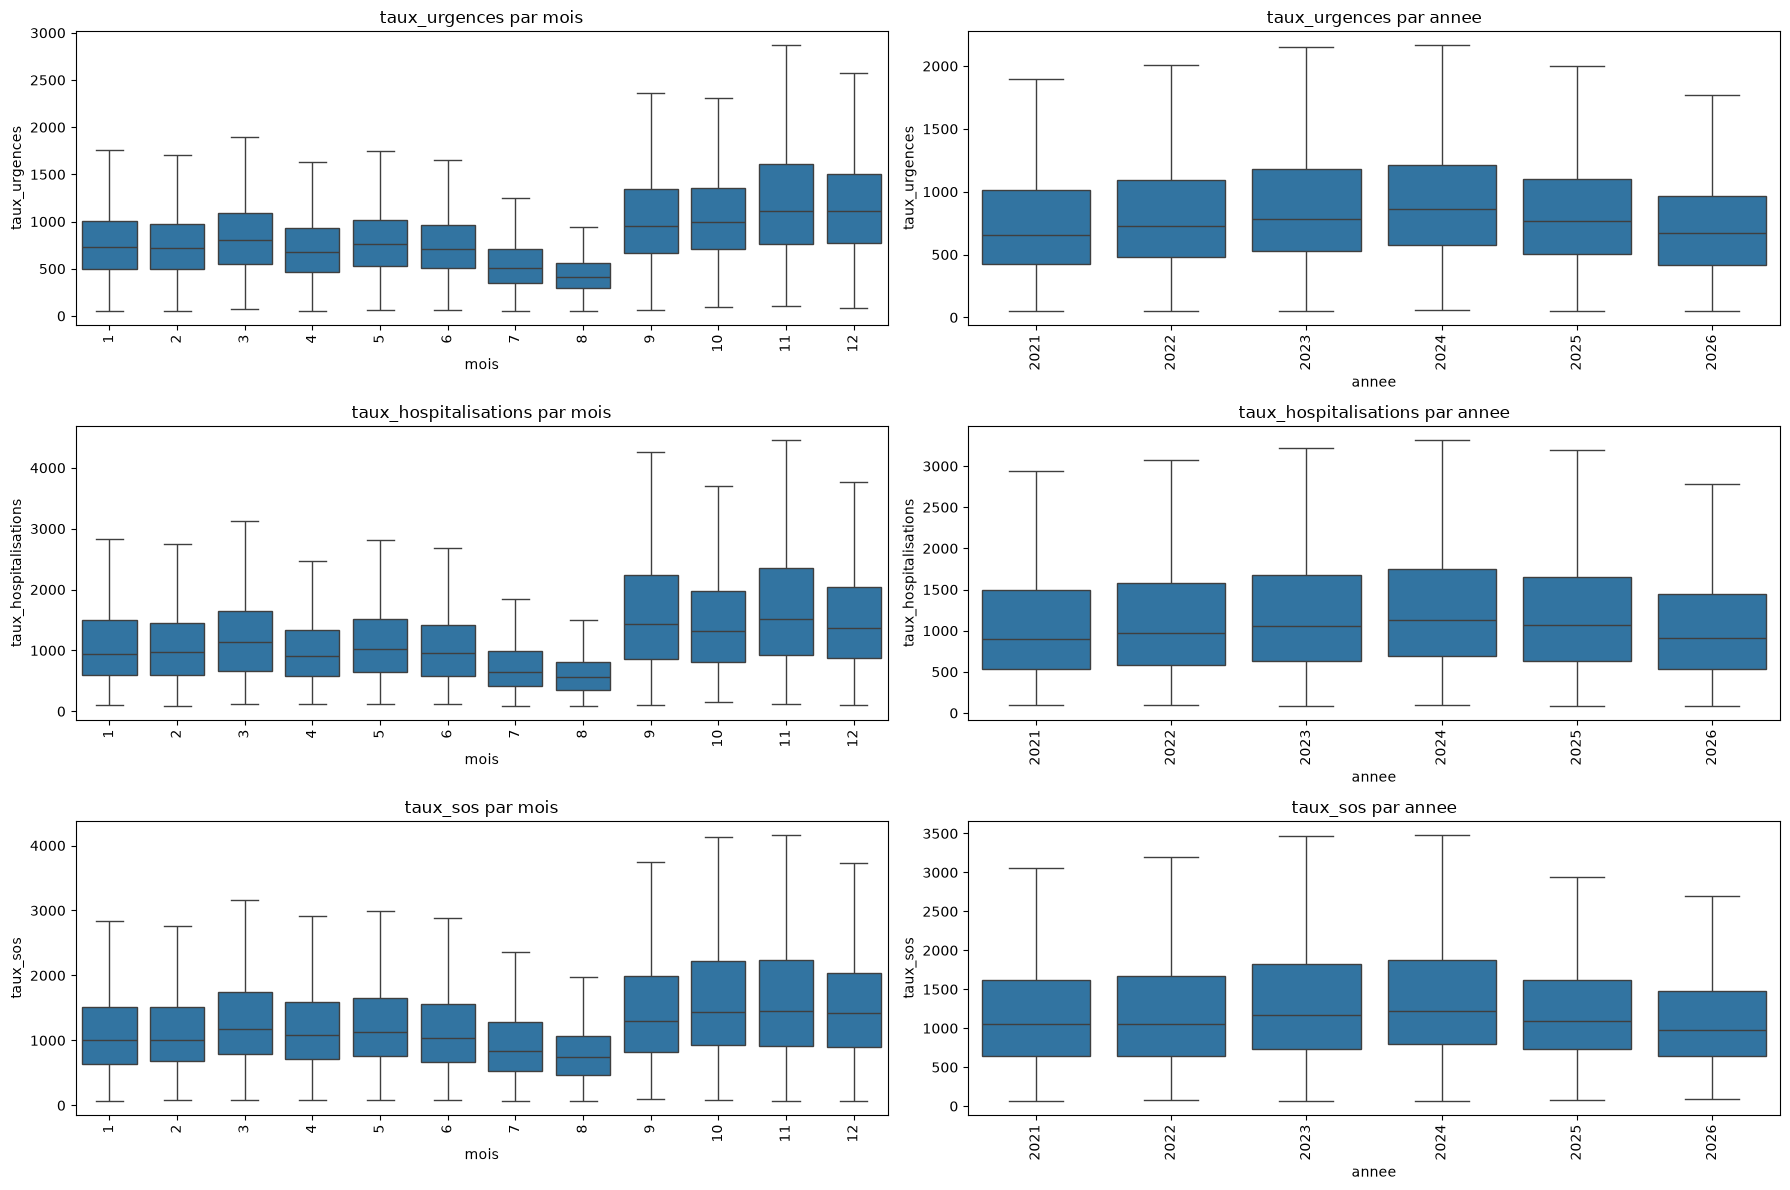

In [7]:
colonnes = ["taux_urgences", "taux_hospitalisations", "taux_sos"]
groupes = ["mois", "annee"]


fig, axes = plt.subplots(3, 2, figsize=(18, 12))

for i, col in enumerate(colonnes):
    for j, groupe in enumerate(groupes):
        sns.boxplot(
            data=df_tous_ages[df_tous_ages[col] > 0],
            x=groupe,
            y=col,
            ax=axes[i, j],
            showfliers=False
        )
        axes[i, j].set_title(f"{col} par {groupe}")
        axes[i, j].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

3. Differences selon categoris de ages

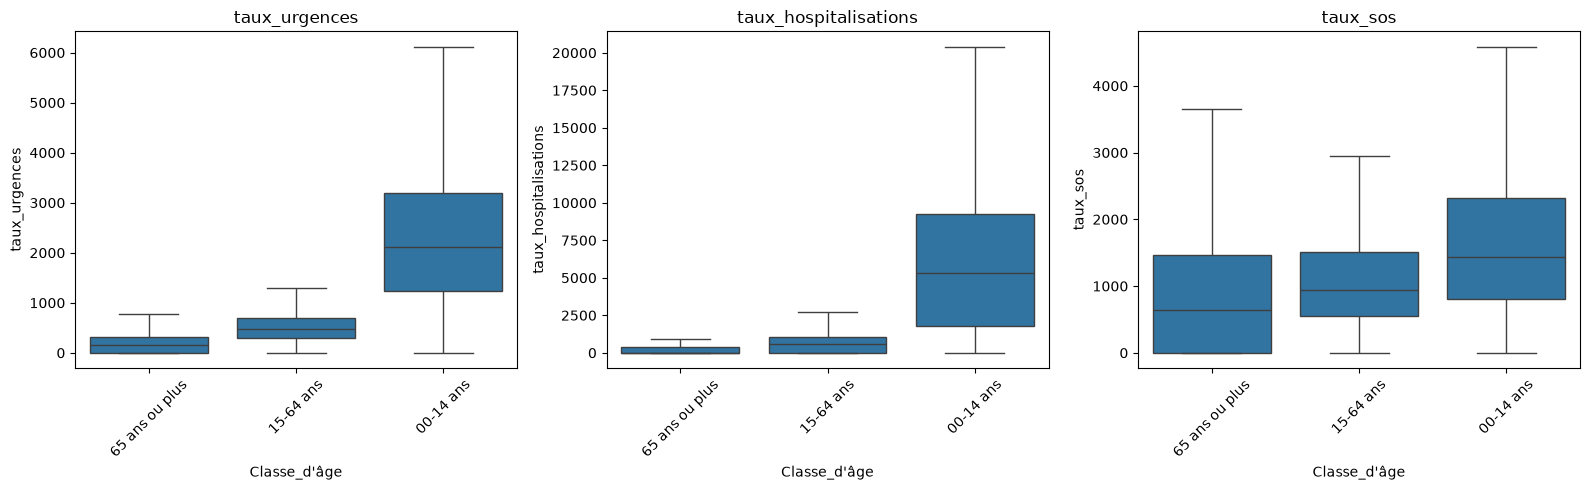

In [8]:
#Taux d'urgences, hospitalisations et SOS medecins par classe d'âge sans valeurs aberrantes/extremes

df_par_ages = df_asthme2.loc[df_asthme2["Classe_d'âge"] != "Tous âges"].copy()     #j'exclu  les lignes correspondant à "Tous âges" pour l'analyse de distribution des taux d'urgences, hospitalisations et SOS medecins


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ["taux_urgences", "taux_hospitalisations", "taux_sos"]):
    sns.boxplot(
        data=df_par_ages,
        x="Classe_d'âge",
        y=col,
        showfliers=False,       #exlure les valeurs aberrantes/extremes
        ax=ax
    )
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Pour les taux d'urgences et SOS medicin la categorie d'age 00-14 ans et le plus representé, et le taux est similaire pour les categories 00-14 et 15-64 ans 

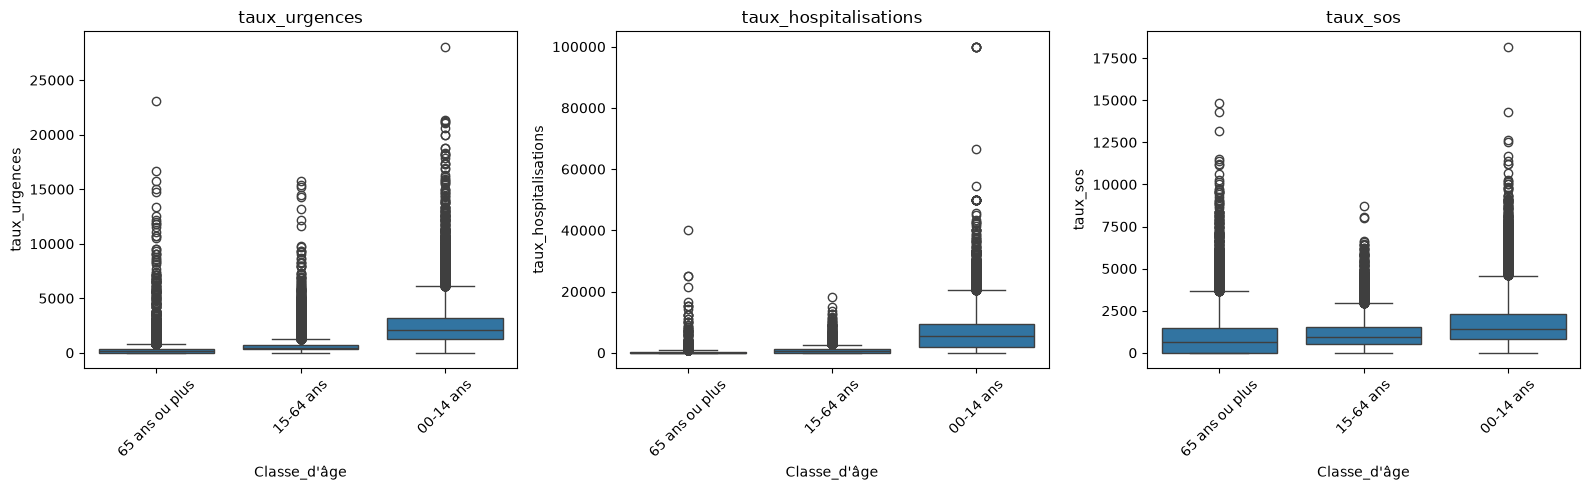

In [9]:
#Taux d'urgences, hospitalisations et SOS medecins par classe d'âge avec valeurs aberrantes/extremes

df_par_ages = df_asthme2.loc[df_asthme2["Classe_d'âge"] != "Tous âges"].copy()     #j'exclu  les lignes correspondant à "Tous âges" pour l'analyse de distribution des taux d'urgences, hospitalisations et SOS medecins
colonnes = ["taux_urgences", "taux_hospitalisations", "taux_sos"]


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ["taux_urgences", "taux_hospitalisations", "taux_sos"]):
    sns.boxplot(
        data=df_par_ages,
        x="Classe_d'âge",
        y=col,
        ax=ax
    )
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

4. Distribution selon le département

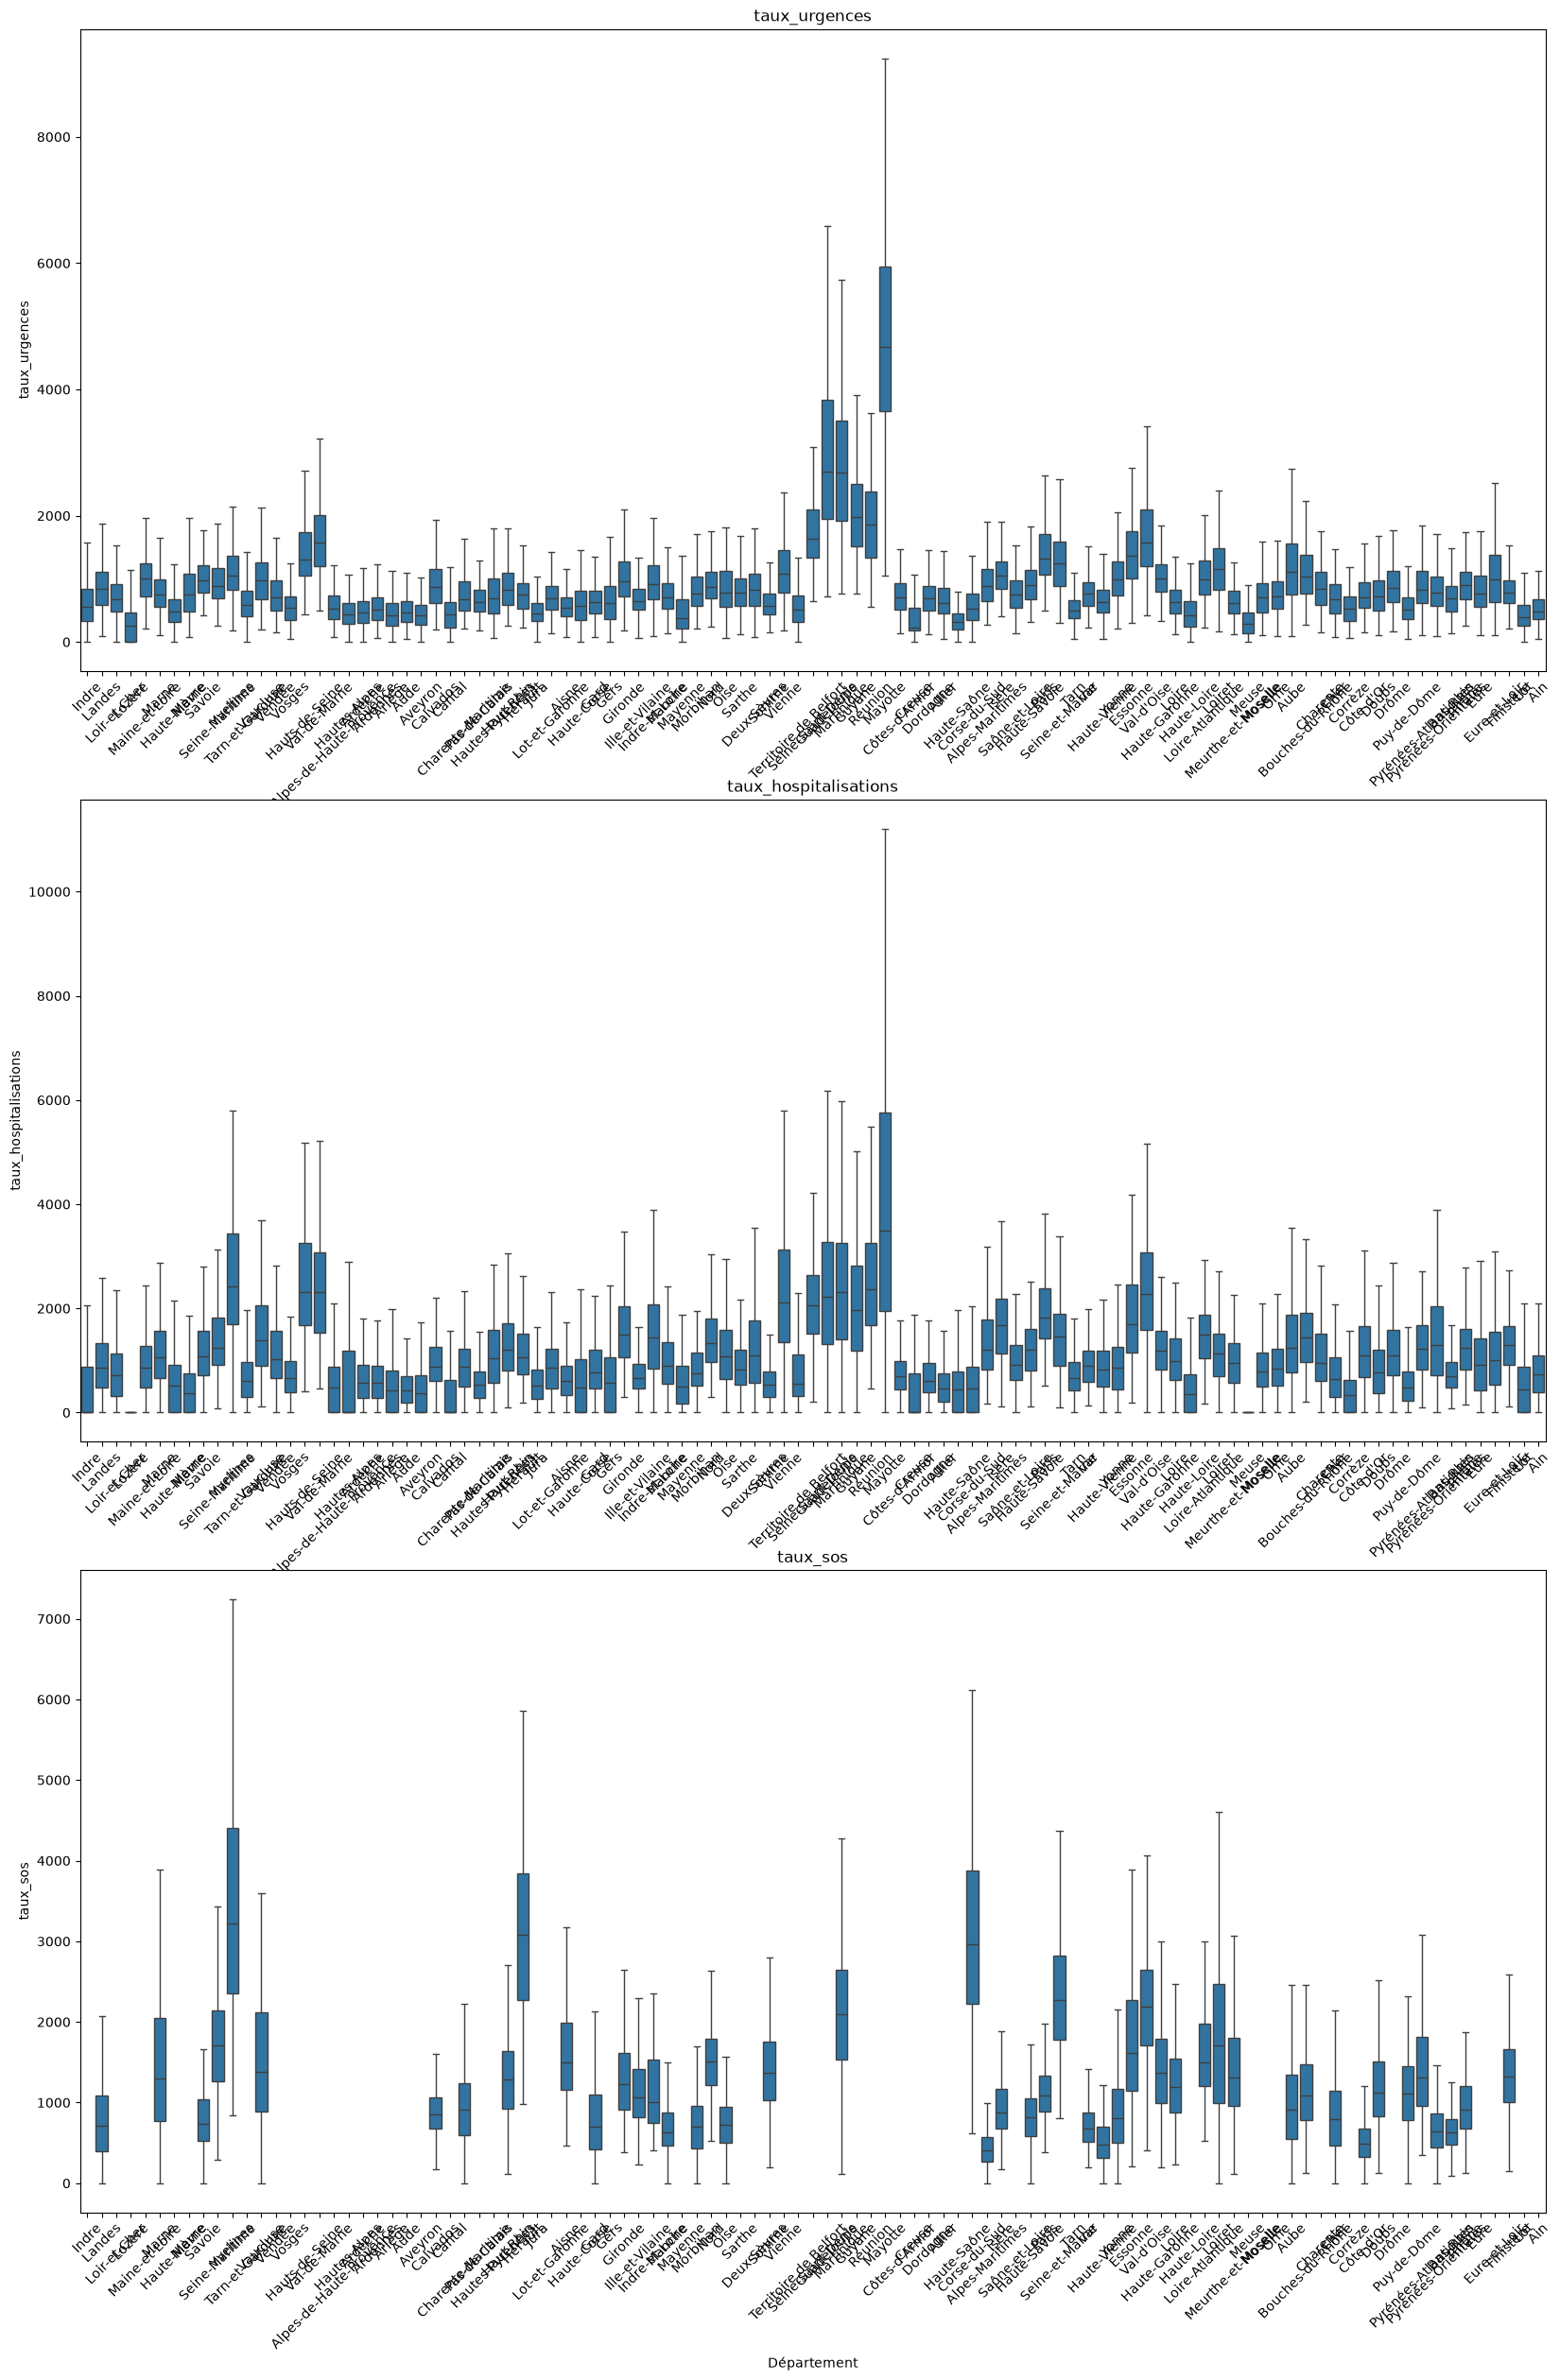

In [10]:
df_tous_ages = df_asthme2.loc[df_asthme2["Classe_d'âge"] == "Tous âges"].copy()     #je selectionne uniquement les lignes correspondant à "Tous âges" pour l'analyse de distribution des taux d'urgences, hospitalisations et SOS medecins
colonnes = ["taux_urgences", "taux_hospitalisations", "taux_sos"]


fig, axes = plt.subplots(3, 1, figsize=(20, 30))

for ax, col in zip(axes, ["taux_urgences", "taux_hospitalisations", "taux_sos"]):
    sns.boxplot(
        data=df_tous_ages,
        x="Département",
        y=col,
        ax=ax,
        showfliers=False
    )
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)


plt.show()

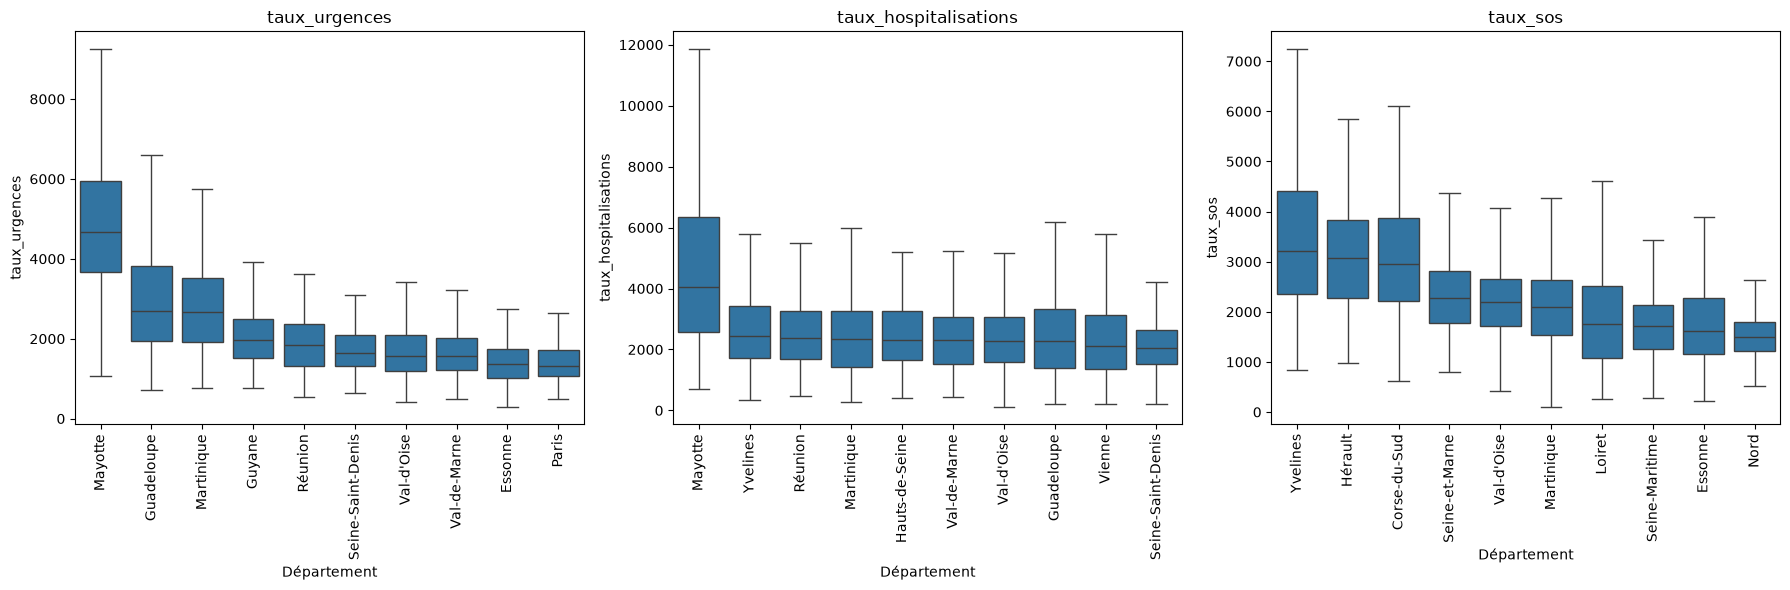

In [11]:
#Departements avec les taux plus elevés

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, col in zip(axes, colonnes):

    df_plot = df_tous_ages[df_tous_ages[col] > 0]

    top10 = (
        df_plot.groupby("Département")[col]
        .median()
        .nlargest(10)
        .index
    )

    sns.boxplot(
        data=df_plot[df_plot["Département"].isin(top10)],
        x="Département",
        y=col,
        order=top10,
        showfliers=False,
        ax=ax
    )

    ax.set_title(col)
    ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

Distribution selon le région

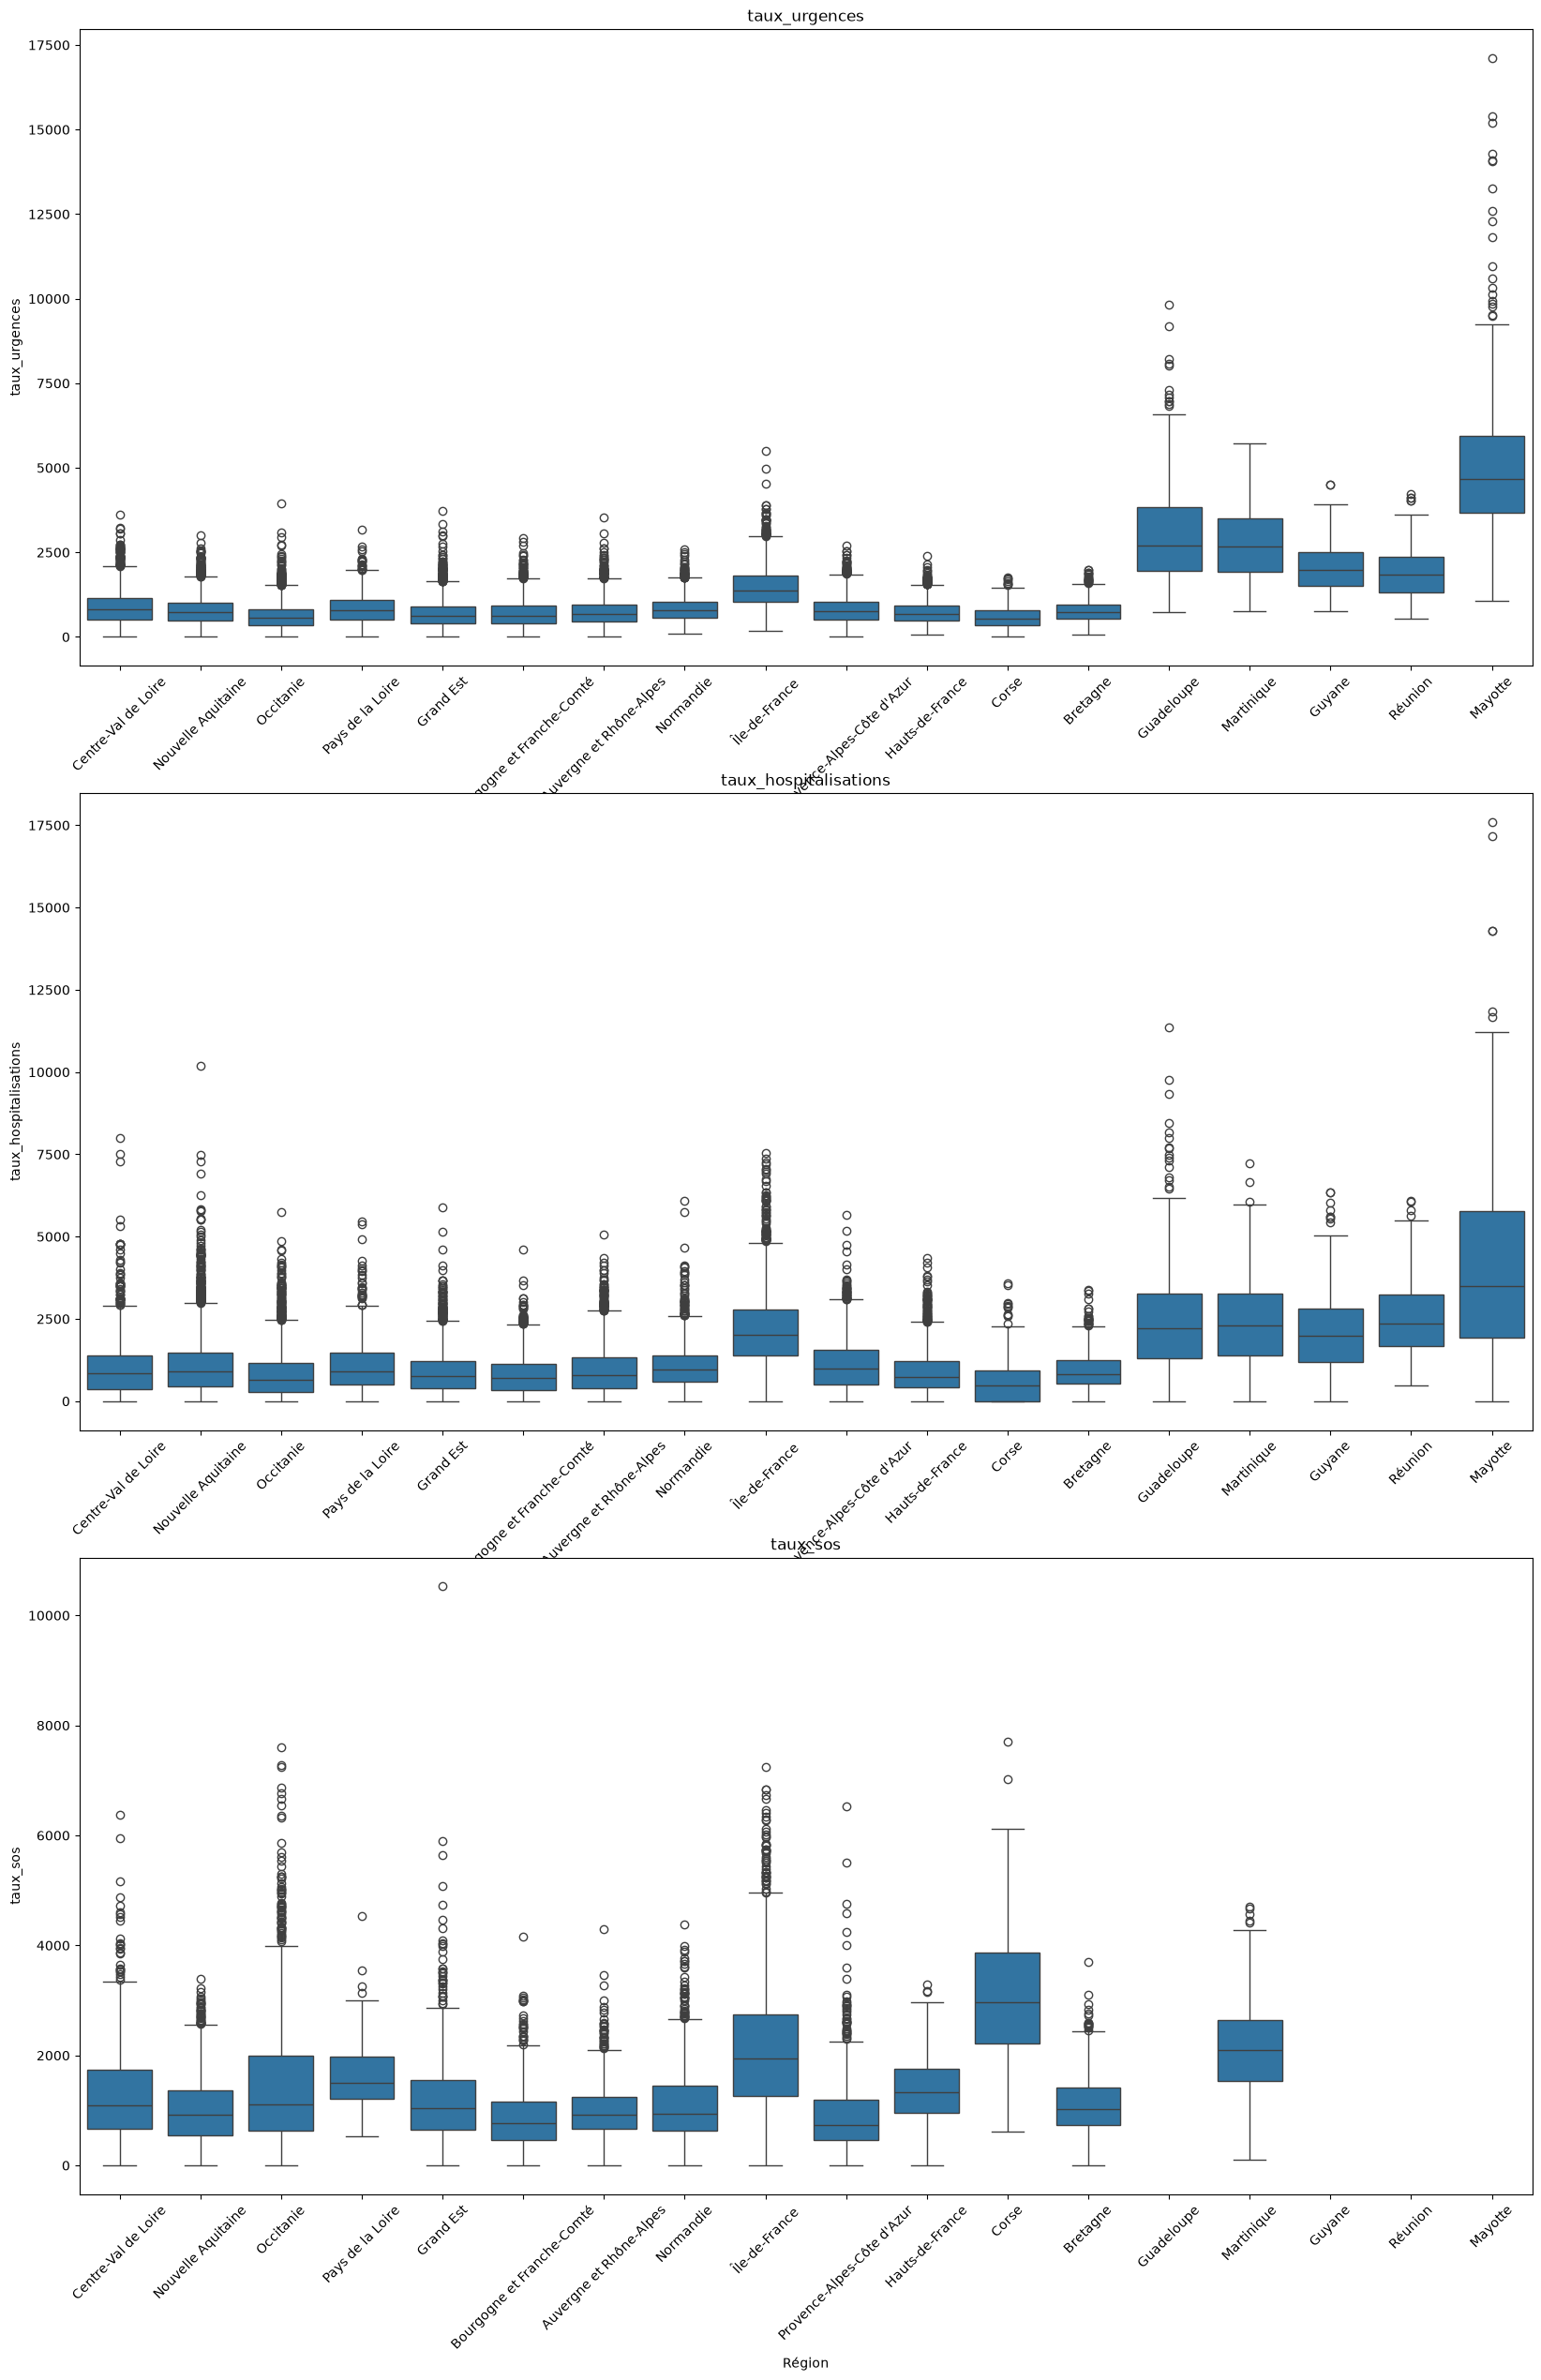

In [12]:
df_tous_ages = df_asthme2.loc[df_asthme2["Classe_d'âge"] == "Tous âges"].copy()     #je selectionne uniquement les lignes correspondant à "Tous âges" pour l'analyse de distribution des taux d'urgences, hospitalisations et SOS medecins
colonnes = ["taux_urgences", "taux_hospitalisations", "taux_sos"]


fig, axes = plt.subplots(3, 1, figsize=(20, 30))

for ax, col in zip(axes, ["taux_urgences", "taux_hospitalisations", "taux_sos"]):
    sns.boxplot(
        data=df_tous_ages,
        x="Région",
        y=col,
        ax=ax,
      
    )
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)


plt.show()

In [13]:
#Évolution hebdomadaire de Taux de passages aux urgences pour asthme pour la catégorie "Tous âges" over all years

asthme_hebdo_urgences = (
    df_asthme2[df_asthme2["Classe_d'âge"] == "Tous âges"]
    .groupby("Semaine")["taux_urgences"]
    .median()
    .reset_index()
)

#Évolution hebdomadaire Taux d'hospitalisations après passages aux urgences pour asthme la catégorie "Tous âges" over all years

asthme_hebdo_hospitalisations = (
    df_asthme2[df_asthme2["Classe_d'âge"] == "Tous âges"]
    .groupby("Semaine")["taux_hospitalisations"]
    .median()
    .reset_index()
)


#Évolution hebdomadaire Taux d'actes médicaux SOS médecins pour asthme pour asthme la catégorie "Tous âges" over all years
asthme_hebdo_actes_sos = (
    df_asthme2[df_asthme2["Classe_d'âge"] == "Tous âges"]
    .groupby("Semaine")["taux_sos"]
    .median()
    .reset_index()
)

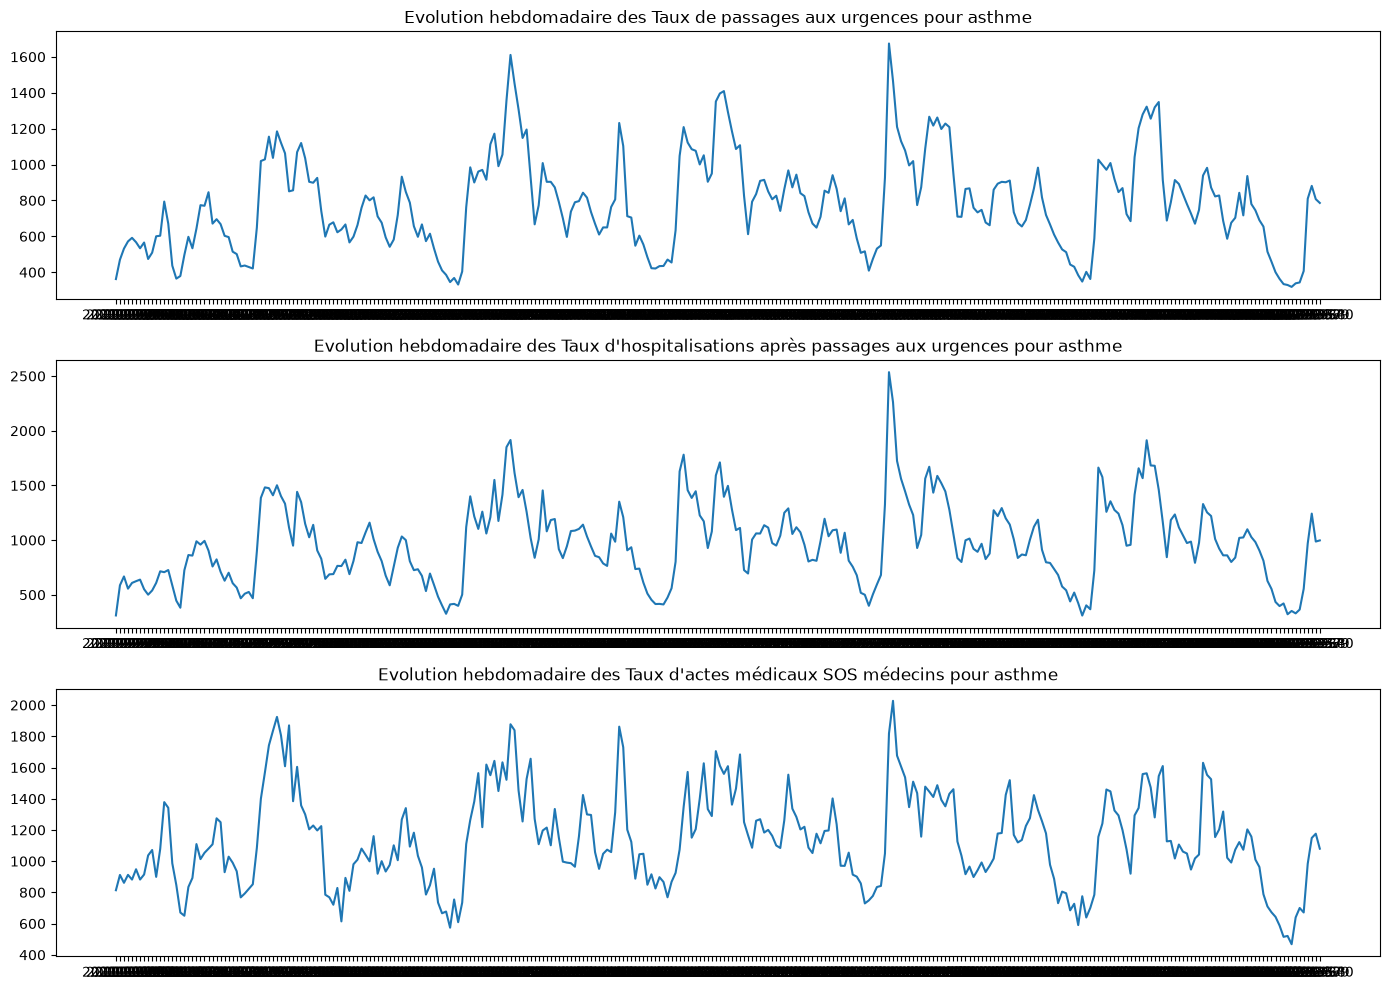

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

axes[0].plot(asthme_hebdo_urgences["Semaine"], asthme_hebdo_urgences["taux_urgences"])
axes[0].set_title("Evolution hebdomadaire des Taux de passages aux urgences pour asthme")

axes[1].plot(asthme_hebdo_hospitalisations["Semaine"], asthme_hebdo_hospitalisations["taux_hospitalisations"])
axes[1].set_title("Evolution hebdomadaire des Taux d'hospitalisations après passages aux urgences pour asthme")

axes[2].plot(asthme_hebdo_actes_sos["Semaine"], asthme_hebdo_actes_sos["taux_sos"])
axes[2].set_title("Evolution hebdomadaire des Taux d'actes médicaux SOS médecins pour asthme")

plt.tight_layout()
plt.show()

Il y a un overlap entre les pics.  

Saisonnalité

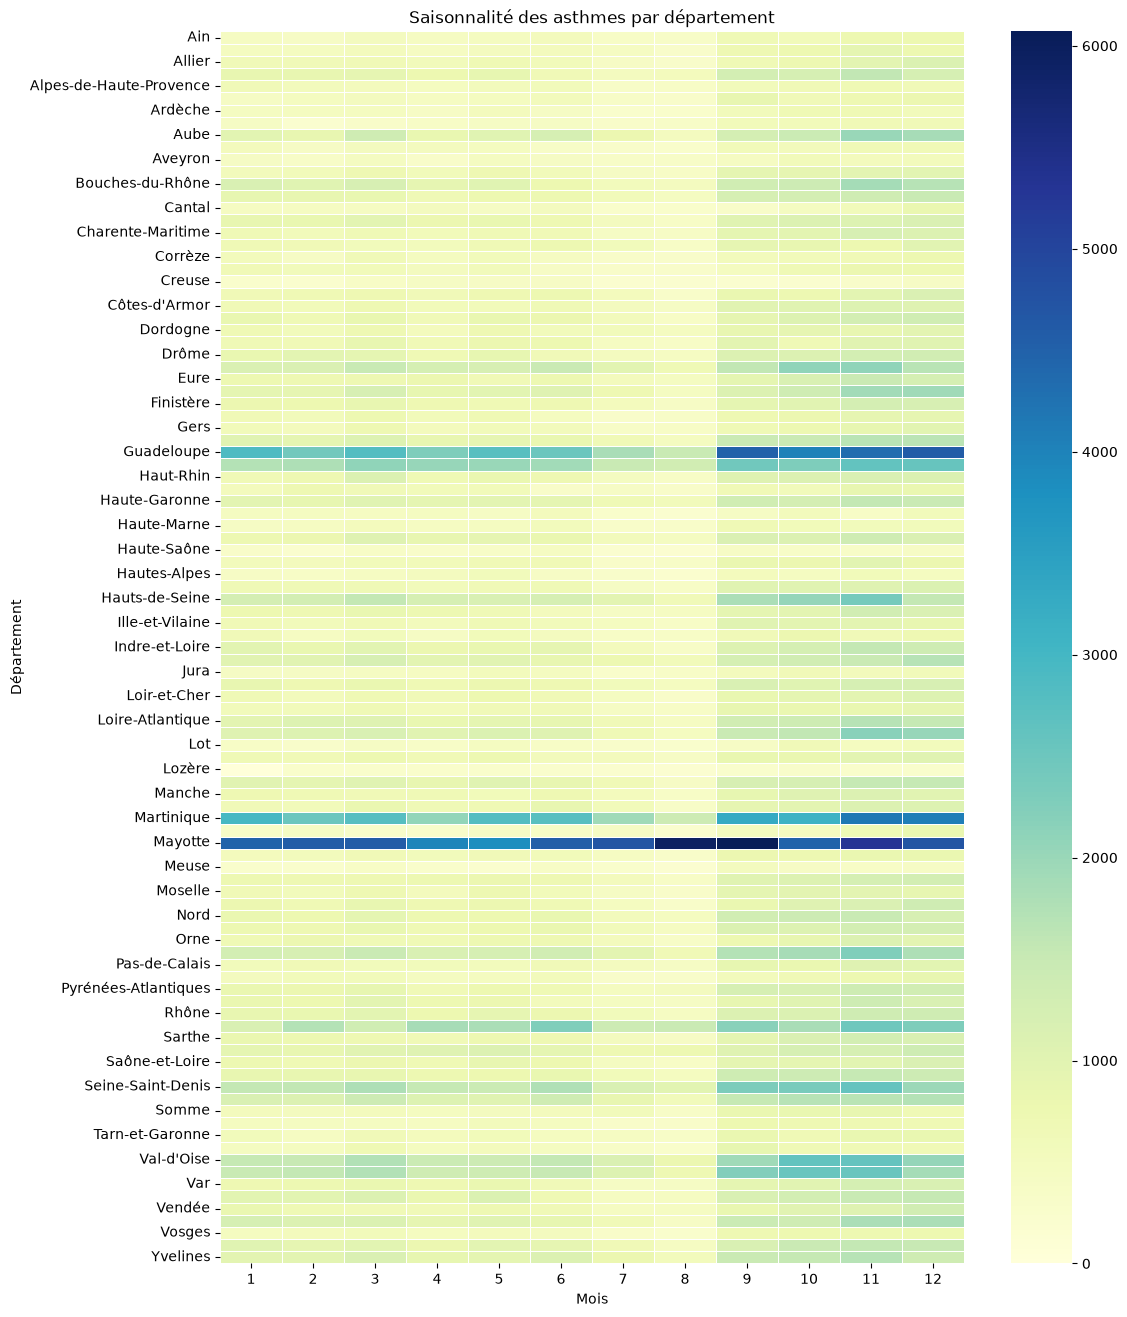

In [15]:
# Médiane descriptive des taux par département et mois
tableau = (
    df_tous_ages.groupby(["Département", "mois"])["taux_urgences"]
    .median()
    .unstack()
)

# Heatmap
plt.figure(figsize=(12, 16))
sns.heatmap(tableau, cmap="YlGnBu", linewidths=.5)

plt.title("Saisonnalité des asthmes par département")
plt.xlabel("Mois")
plt.ylabel("Département")
plt.show()

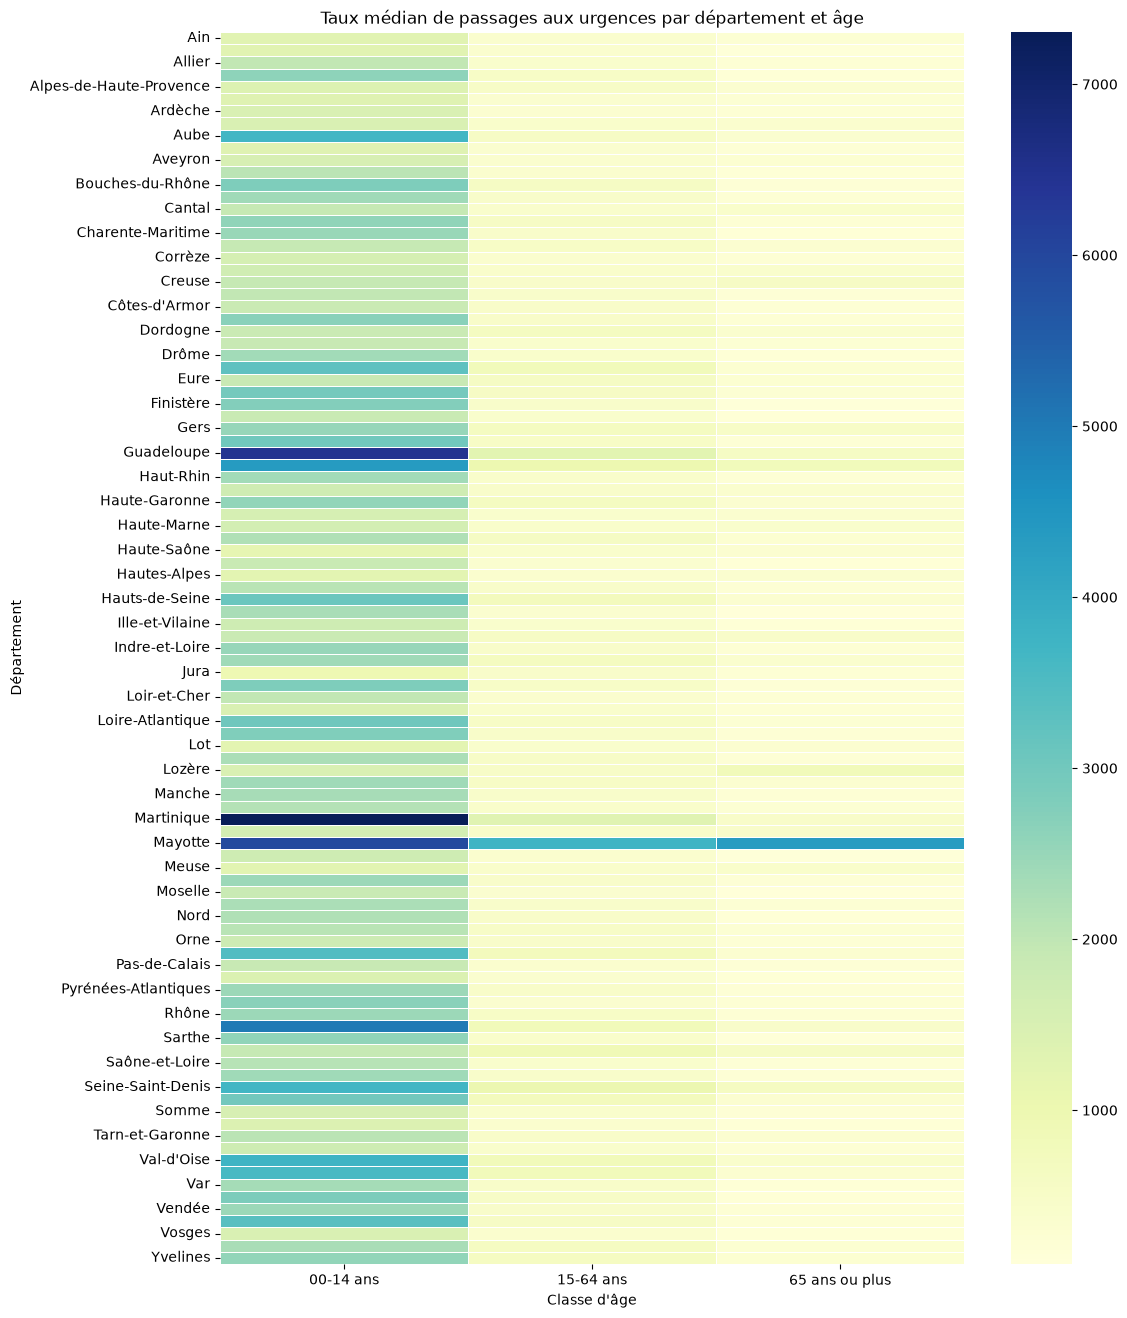

In [16]:
# Médiane descriptive des taux par département et classe d'age
tableau2 = (
    df_par_ages[df_par_ages["taux_urgences"] > 0].groupby(["Département", "Classe_d'âge"])["taux_urgences"]
    .median()
    .unstack()
)

# Heatmap
plt.figure(figsize=(12, 16))
sns.heatmap(tableau2, cmap="YlGnBu", linewidths=.5)

plt.title("Taux médian de passages aux urgences par département et âge")
plt.xlabel("Classe d'âge")
plt.ylabel("Département")
plt.show()

Saisonnalité

In [17]:

# Calculer la médiane des taux par mois over the years
saisonnalite_urgences = (
    df_tous_ages.groupby("mois")["taux_urgences"]
    .median()
    .reset_index()
)

saisonnalite_hospitalisation = (
    df_tous_ages.groupby("mois")["taux_hospitalisations"]
    .median()
    .reset_index()
)

saisonnalite_sos = (
    df_tous_ages.groupby("mois")["taux_sos"]
    .median()
    .reset_index()
)

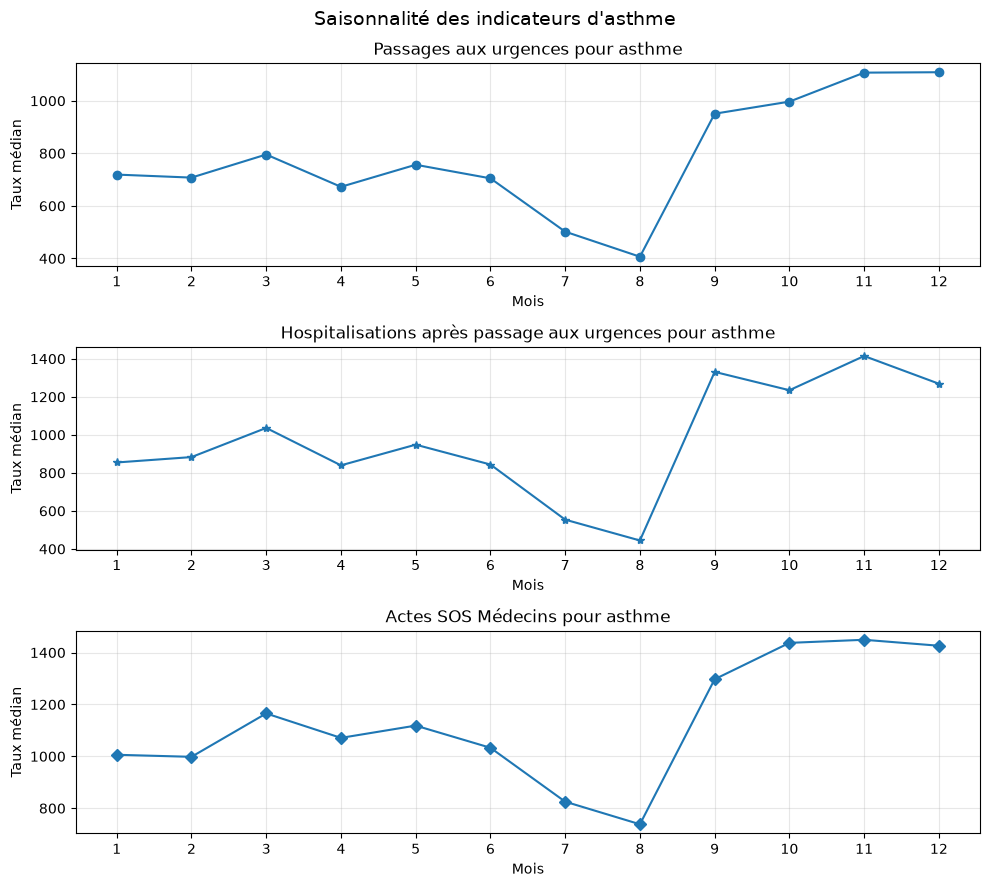

In [18]:
# Visualiser la saisonnalité
fig, axes = plt.subplots(3, 1, figsize=(10, 9))

# Passages aux urgences
axes[0].plot(saisonnalite_urgences.mois, saisonnalite_urgences.taux_urgences, marker="o")
axes[0].set_title("Passages aux urgences pour asthme")
axes[0].set_ylabel("Taux médian")

# Hospitalisations
axes[1].plot(saisonnalite_hospitalisation.mois, saisonnalite_hospitalisation.taux_hospitalisations, marker="*")
axes[1].set_title("Hospitalisations après passage aux urgences pour asthme")
axes[1].set_ylabel("Taux médian")

# Actes SOS Médecins
axes[2].plot(saisonnalite_sos.mois, saisonnalite_sos.taux_sos, marker="D")
axes[2].set_title("Actes SOS Médecins pour asthme")
axes[2].set_ylabel("Taux médian")

# Mise en forme commune
for ax in axes:
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Mois")
    ax.grid(alpha=0.3)

fig.suptitle("Saisonnalité des indicateurs d'asthme", fontsize=14)
plt.tight_layout()
plt.show()     

Vérifier si le  (pic aux urgences) se répète chaque année

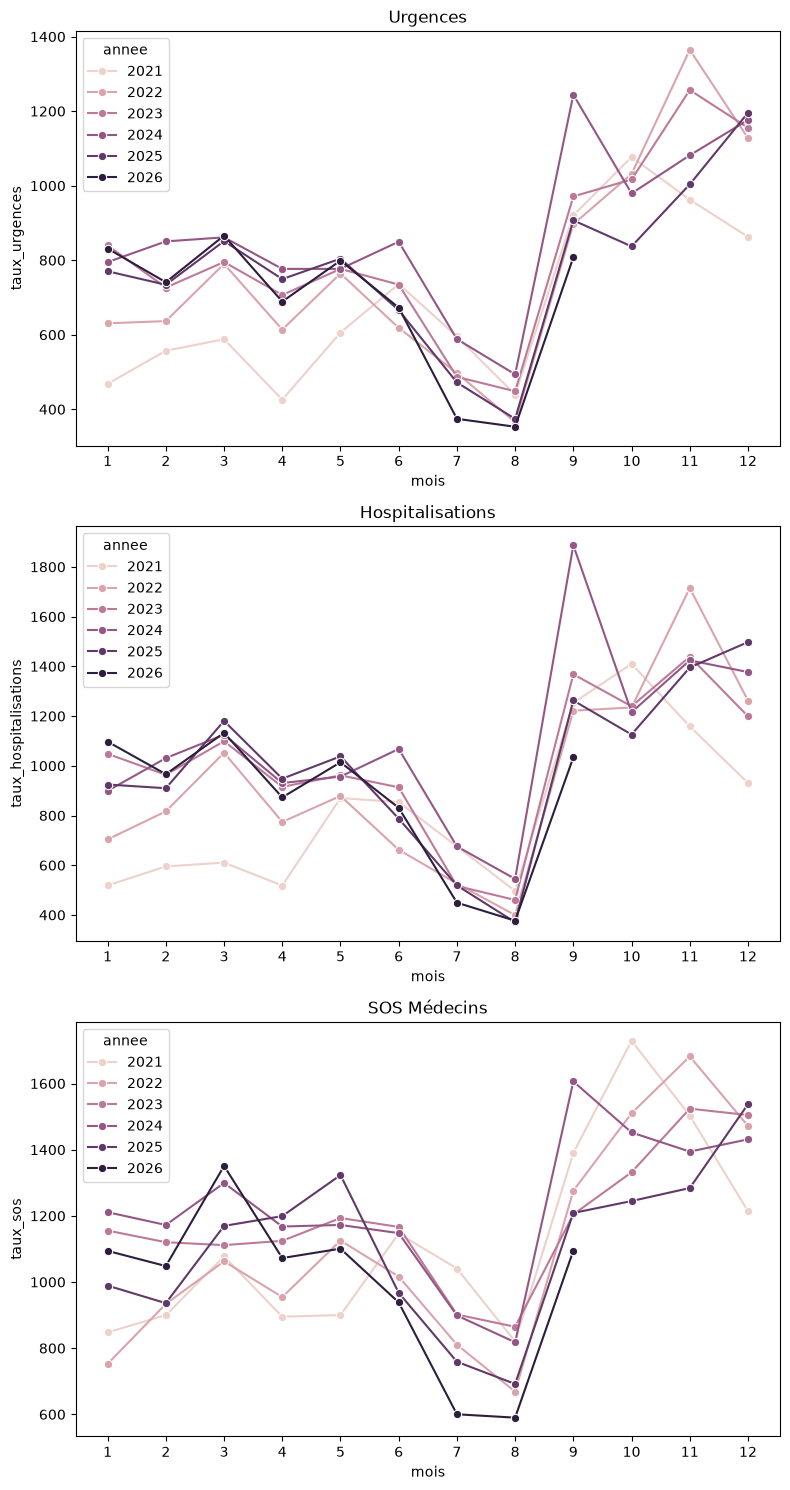

In [19]:
colonnes = ["taux_urgences", "taux_hospitalisations", "taux_sos"]
titres = ["Urgences", "Hospitalisations", "SOS Médecins"]

# Calcul des médianes par année et par mois
saisonnalite = (
    df_tous_ages.groupby(["annee", "mois"])[colonnes]
    .median()
    .reset_index()
)


# Visualisation
fig, axes = plt.subplots(3, 1, figsize=(8, 15))

for i, col in enumerate(colonnes):
    sns.lineplot(
        data=saisonnalite,
        x="mois",
        y=col,
        hue="annee",
        marker="o",
        ax=axes[i]
    )

    axes[i].set_title(titres[i])
    axes[i].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()